# Predicting C and O abundances with LGBM

This notebook tests whether `zmax`, `rperi`, and `P_gal` improve the prediction of `o_h` and `c_h`, and compares four chemistry encodings:

- `fe_h`, `mg_h`, `si_h`
- `fe_h`, `alpha_mean` where `alpha_mean = (mg_h + si_h) / 2`
- `fe_h`, `mg_h`
- `fe_h`, `si_h`


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


In [15]:
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc("axes", labelweight="bold", labelsize="large", titleweight="bold", titlesize=14, titlepad=10)

random_state = 42


## Load and clean data

In [16]:
apogee = pd.read_csv("apogee_sample.csv")
harps = pd.read_csv("harps_sample.csv")

print(f"Raw APOGEE rows: {len(apogee)}")
print(f"Raw HARPS rows:  {len(harps)}")


Raw APOGEE rows: 95586
Raw HARPS rows:  798


In [17]:
def clean_survey_data(df, survey_name):
    df = df.copy()

    df = df[df["parallax"] > 0.0]
    df["rel_parallax"] = df["parallax_error"] / df["parallax"]
    df = df[df["rel_parallax"] < 0.1]

    if survey_name.lower() == "apogee":
        df = df[df["logg"] < 3]
    elif survey_name.lower() == "harps":
        df = df[df["zmax"] < 10]

    df = df[df["zmax"] < 10]

    required_columns = ["fe_h", "mg_h", "si_h", "zmax", "rperi", "P_gal"]
    df = df.dropna(subset=required_columns)

    df["alpha_mean"] = (df["mg_h"] + df["si_h"]) / 2.0
    return df


apogee = clean_survey_data(apogee, "apogee")
harps = clean_survey_data(harps, "harps")

print(f"Clean APOGEE rows: {len(apogee)}")
print(f"Clean HARPS rows:  {len(harps)}")


Clean APOGEE rows: 45727
Clean HARPS rows:  798


In [18]:
base_columns = ["fe_h", "mg_h", "si_h", "alpha_mean", "o_h", "c_h", "zmax", "rperi", "P_gal"]
apogee = apogee[base_columns].copy()
harps = harps[base_columns].copy()

apogee.head()


,fe_h,mg_h,si_h,alpha_mean,o_h,c_h,zmax,rperi,P_gal
2,-0.08,-0.08,-0.07,-0.075,-0.04,-0.27,0.274214,10.903978,96.4
3,-0.28,-0.20,-0.26,-0.230,-0.18,-0.39,0.398805,6.557123,97.3
6,-0.26,-0.15,-0.14,-0.145,-0.22,-0.73,0.523406,9.156036,94.9
7,0.05,0.10,0.05,0.075,0.11,0.01,0.450359,6.926147,95.4
8,0.03,0.10,0.11,0.105,0.08,0.02,0.477434,7.004757,28.3


## Define feature configurations

In [19]:
TARGETS = ["o_h", "c_h"]

CHEMISTRY_CONFIGS = {
    "fe_mg_si": ["fe_h", "mg_h", "si_h"],
    "fe_alpha_mean": ["fe_h", "alpha_mean"],
    "fe_mg": ["fe_h", "mg_h"],
    "fe_si": ["fe_h", "si_h"],
}

ORBIT_CONFIGS = {
    "chem_only": [],
    "plus_zmax": ["zmax"],
    "plus_rperi": ["rperi"],
    "plus_pgal": ["P_gal"],
    "plus_all_orbits": ["zmax", "rperi", "P_gal"],
}

experiment_rows = []
for target in TARGETS:
    for chemistry_name, chemistry_features in CHEMISTRY_CONFIGS.items():
        for orbit_name, orbit_features in ORBIT_CONFIGS.items():
            feature_list = chemistry_features + orbit_features
            experiment_rows.append(
                {
                    "target": target,
                    "chemistry_mode": chemistry_name,
                    "orbit_mode": orbit_name,
                    "features": feature_list,
                }
            )

experiment_df = pd.DataFrame(experiment_rows)
experiment_df


,target,chemistry_mode,orbit_mode,features
0,o_h,fe_mg_si,chem_only,"[fe_h, mg_h, si_h]"
1,o_h,fe_mg_si,plus_zmax,"[fe_h, mg_h, si_h, zmax]"
2,o_h,fe_mg_si,plus_rperi,"[fe_h, mg_h, si_h, rperi]"
3,o_h,fe_mg_si,plus_pgal,"[fe_h, mg_h, si_h, P_gal]"
4,o_h,fe_mg_si,plus_all_orbits,"[fe_h, mg_h, si_h, zmax, rperi, P_gal]"
5,o_h,fe_alpha_mean,chem_only,"[fe_h, alpha_mean]"
6,o_h,fe_alpha_mean,plus_zmax,"[fe_h, alpha_mean, zmax]"
7,o_h,fe_alpha_mean,plus_rperi,"[fe_h, alpha_mean, rperi]"
8,o_h,fe_alpha_mean,plus_pgal,"[fe_h, alpha_mean, P_gal]"
9,o_h,fe_alpha_mean,plus_all_orbits,"[fe_h, alpha_mean, zmax, rperi, P_gal]"


## Train and evaluate LGBM

In [20]:
def compute_metrics(y_true, y_pred):
    return {
        "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def run_lgbm_experiment(apogee_df, harps_df, target, features, random_state=42):
    train_cols = features + [target]

    apogee_model_df = apogee_df[train_cols].dropna().copy()
    harps_model_df = harps_df[train_cols].dropna().copy()

    X = apogee_model_df[features]
    y = apogee_model_df[target]

    X_train, X_val, y_train, y_val = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=random_state,
    )

    model = LGBMRegressor(
        random_state=random_state,
        verbosity=-1,
        n_jobs=-1,
        objective="regression",
    )
    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    harps_pred = model.predict(harps_model_df[features])

    val_metrics = compute_metrics(y_val, val_pred)
    harps_metrics = compute_metrics(harps_model_df[target], harps_pred)

    result = {
        "n_apogee": len(apogee_model_df),
        "n_harps": len(harps_model_df),
        "n_features": len(features),
        "features": ", ".join(features),
        "val_rmse": val_metrics["rmse"],
        "val_mae": val_metrics["mae"],
        "val_r2": val_metrics["r2"],
        "harps_rmse": harps_metrics["rmse"],
        "harps_mae": harps_metrics["mae"],
        "harps_r2": harps_metrics["r2"],
    }
    return result, model


In [21]:
results = []
trained_models = {}

for row in experiment_rows:
    result, model = run_lgbm_experiment(
        apogee_df=apogee,
        harps_df=harps,
        target=row["target"],
        features=row["features"],
        random_state=random_state,
    )

    results.append({**row, **result})
    trained_models[(row["target"], row["chemistry_mode"], row["orbit_mode"])] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(["target", "chemistry_mode", "val_rmse"]).reset_index(drop=True)
results_df


,target,chemistry_mode,orbit_mode,features,n_apogee,n_harps,n_features,val_rmse,val_mae,val_r2,harps_rmse,harps_mae,harps_r2
0,c_h,fe_alpha_mean,plus_all_orbits,"fe_h, alpha_mean, zmax, rperi, P_gal",45727,627,5,0.068798,0.047392,0.919076,0.103069,0.087203,0.776886
1,c_h,fe_alpha_mean,plus_rperi,"fe_h, alpha_mean, rperi",45727,627,3,0.069164,0.047883,0.918213,0.099416,0.083746,0.792424
2,c_h,fe_alpha_mean,plus_pgal,"fe_h, alpha_mean, P_gal",45727,627,3,0.069382,0.047972,0.917695,0.109300,0.092277,0.749097
3,c_h,fe_alpha_mean,plus_zmax,"fe_h, alpha_mean, zmax",45727,627,3,0.069465,0.047866,0.917499,0.110198,0.093798,0.744954
4,c_h,fe_alpha_mean,chem_only,"fe_h, alpha_mean",45727,627,2,0.069788,0.048223,0.916730,0.107783,0.091135,0.756014
5,c_h,fe_mg,plus_all_orbits,"fe_h, mg_h, zmax, rperi, P_gal",45727,627,5,0.067392,0.046138,0.922350,0.109686,0.093120,0.747322
6,c_h,fe_mg,plus_rperi,"fe_h, mg_h, rperi",45727,627,3,0.067566,0.046405,0.921948,0.108035,0.091158,0.754871
7,c_h,fe_mg,plus_pgal,"fe_h, mg_h, P_gal",45727,627,3,0.067928,0.046643,0.921108,0.116893,0.098851,0.713027
8,c_h,fe_mg,plus_zmax,"fe_h, mg_h, zmax",45727,627,3,0.068045,0.046605,0.920837,0.118207,0.100891,0.706535
9,c_h,fe_mg,chem_only,"fe_h, mg_h",45727,627,2,0.068274,0.046800,0.920304,0.116988,0.099165,0.712560


## Summary tables

In [22]:
summary_columns = [
    "target",
    "chemistry_mode",
    "orbit_mode",
    "features",
    "val_rmse",
    "val_mae",
    "val_r2",
    "harps_rmse",
    "harps_mae",
    "harps_r2",
]

results_df[summary_columns].round(4)


,target,chemistry_mode,orbit_mode,features,val_rmse,val_mae,val_r2,harps_rmse,harps_mae,harps_r2
0,c_h,fe_alpha_mean,plus_all_orbits,"fe_h, alpha_mean, zmax, rperi, P_gal",0.0688,0.0474,0.9191,0.1031,0.0872,0.7769
1,c_h,fe_alpha_mean,plus_rperi,"fe_h, alpha_mean, rperi",0.0692,0.0479,0.9182,0.0994,0.0837,0.7924
2,c_h,fe_alpha_mean,plus_pgal,"fe_h, alpha_mean, P_gal",0.0694,0.0480,0.9177,0.1093,0.0923,0.7491
3,c_h,fe_alpha_mean,plus_zmax,"fe_h, alpha_mean, zmax",0.0695,0.0479,0.9175,0.1102,0.0938,0.7450
4,c_h,fe_alpha_mean,chem_only,"fe_h, alpha_mean",0.0698,0.0482,0.9167,0.1078,0.0911,0.7560
5,c_h,fe_mg,plus_all_orbits,"fe_h, mg_h, zmax, rperi, P_gal",0.0674,0.0461,0.9224,0.1097,0.0931,0.7473
6,c_h,fe_mg,plus_rperi,"fe_h, mg_h, rperi",0.0676,0.0464,0.9219,0.1080,0.0912,0.7549
7,c_h,fe_mg,plus_pgal,"fe_h, mg_h, P_gal",0.0679,0.0466,0.9211,0.1169,0.0989,0.7130
8,c_h,fe_mg,plus_zmax,"fe_h, mg_h, zmax",0.0680,0.0466,0.9208,0.1182,0.1009,0.7065
9,c_h,fe_mg,chem_only,"fe_h, mg_h",0.0683,0.0468,0.9203,0.1170,0.0992,0.7126


In [23]:
best_by_validation = (
    results_df.sort_values("val_rmse")
    .groupby(["target", "chemistry_mode"], as_index=False)
    .first()
)

best_by_validation[["target", "chemistry_mode", "orbit_mode", "features", "val_rmse", "harps_rmse"]].round(4)


,target,chemistry_mode,orbit_mode,features,val_rmse,harps_rmse
0,c_h,fe_alpha_mean,plus_all_orbits,"fe_h, alpha_mean, zmax, rperi, P_gal",0.0688,0.1031
1,c_h,fe_mg,plus_all_orbits,"fe_h, mg_h, zmax, rperi, P_gal",0.0674,0.1097
2,c_h,fe_mg_si,plus_all_orbits,"fe_h, mg_h, si_h, zmax, rperi, P_gal",0.0673,0.1106
3,c_h,fe_si,plus_all_orbits,"fe_h, si_h, zmax, rperi, P_gal",0.0731,0.0968
4,o_h,fe_alpha_mean,plus_all_orbits,"fe_h, alpha_mean, zmax, rperi, P_gal",0.0367,0.0899
5,o_h,fe_mg,plus_all_orbits,"fe_h, mg_h, zmax, rperi, P_gal",0.0376,0.0881
6,o_h,fe_mg_si,plus_pgal,"fe_h, mg_h, si_h, P_gal",0.0360,0.0889
7,o_h,fe_si,plus_all_orbits,"fe_h, si_h, zmax, rperi, P_gal",0.0398,0.0946


## Compare orbital-feature impact

In [24]:
baseline_rows = (
    results_df[results_df["orbit_mode"] == "chem_only"]
    [["target", "chemistry_mode", "val_rmse", "val_mae", "harps_rmse", "harps_mae"]]
    .rename(
        columns={
            "val_rmse": "val_rmse_base",
            "val_mae": "val_mae_base",
            "harps_rmse": "harps_rmse_base",
            "harps_mae": "harps_mae_base",
        }
    )
)

comparison_df = results_df.merge(baseline_rows, on=["target", "chemistry_mode"], how="left")
comparison_df["delta_val_rmse"] = comparison_df["val_rmse"] - comparison_df["val_rmse_base"]
comparison_df["delta_val_mae"] = comparison_df["val_mae"] - comparison_df["val_mae_base"]
comparison_df["delta_harps_rmse"] = comparison_df["harps_rmse"] - comparison_df["harps_rmse_base"]
comparison_df["delta_harps_mae"] = comparison_df["harps_mae"] - comparison_df["harps_mae_base"]

comparison_df[[
    "target",
    "chemistry_mode",
    "orbit_mode",
    "delta_val_rmse",
    "delta_val_mae",
    "delta_harps_rmse",
    "delta_harps_mae",
]].round(4)


,target,chemistry_mode,orbit_mode,delta_val_rmse,delta_val_mae,delta_harps_rmse,delta_harps_mae
0,c_h,fe_alpha_mean,plus_all_orbits,-0.0010,-0.0008,-0.0047,-0.0039
1,c_h,fe_alpha_mean,plus_rperi,-0.0006,-0.0003,-0.0084,-0.0074
2,c_h,fe_alpha_mean,plus_pgal,-0.0004,-0.0003,0.0015,0.0011
3,c_h,fe_alpha_mean,plus_zmax,-0.0003,-0.0004,0.0024,0.0027
4,c_h,fe_alpha_mean,chem_only,0.0000,0.0000,0.0000,0.0000
5,c_h,fe_mg,plus_all_orbits,-0.0009,-0.0007,-0.0073,-0.0060
6,c_h,fe_mg,plus_rperi,-0.0007,-0.0004,-0.0090,-0.0080
7,c_h,fe_mg,plus_pgal,-0.0003,-0.0002,-0.0001,-0.0003
8,c_h,fe_mg,plus_zmax,-0.0002,-0.0002,0.0012,0.0017
9,c_h,fe_mg,chem_only,0.0000,0.0000,0.0000,0.0000


## Compare chemistry encodings

In [25]:
chemistry_comparison = (
    results_df.pivot_table(
        index=["target", "orbit_mode"],
        columns="chemistry_mode",
        values=["val_rmse", "val_mae", "harps_rmse", "harps_mae"],
    )
)

chemistry_comparison.round(4)


harps_mae                             harps_rmse  \
chemistry_mode         fe_alpha_mean   fe_mg fe_mg_si   fe_si fe_alpha_mean   
target orbit_mode                                                             
c_h    chem_only              0.0911  0.0992   0.0990  0.0811        0.1078   
       plus_all_orbits        0.0872  0.0931   0.0939  0.0810        0.1031   
       plus_pgal              0.0923  0.0989   0.0994  0.0836        0.1093   
       plus_rperi             0.0837  0.0912   0.0920  0.0725        0.0994   
       plus_zmax              0.0938  0.1009   0.1008  0.0887        0.1102   
o_h    chem_only              0.0662  0.0641   0.0639  0.0753        0.0903   
       plus_all_orbits        0.0655  0.0638   0.0635  0.0705        0.0899   
       plus_pgal              0.0651  0.0636   0.0634  0.0725        0.0891   
       plus_rperi             0.0654  0.0632   0.0631  0.0738        0.0894   
       plus_zmax              0.0657  0.0649   0.0643  0.0729        0.0900   

                                                      val_mae          \
chemistry_mode           fe_mg fe_mg_si   fe_si fe_alpha_mean   fe_mg   
target orbit_mode                                                       
c_h    chem_only        0.1170   0.1167  0.0972        0.0482  0.0468   
       plus_all_orbits  0.1097   0.1106  0.0968        0.0474  0.0461   
       plus_pgal        0.1169   0.1173  0.1000        0.0480  0.0466   
       plus_rperi       0.1080   0.1088  0.0884        0.0479  0.0464   
       plus_zmax        0.1182   0.1182  0.1047        0.0479  0.0466   
o_h    chem_only        0.0882   0.0895  0.0989        0.0244  0.0248   
       plus_all_orbits  0.0881   0.0890  0.0946        0.0242  0.0245   
       plus_pgal        0.0880   0.0889  0.0964        0.0242  0.0247   
       plus_rperi       0.0870   0.0887  0.0969        0.0243  0.0247   
       plus_zmax        0.0896   0.0899  0.0972        0.0244  0.0248   

                                             val_rmse                           
chemistry_mode         fe_mg_si   fe_si fe_alpha_mean   fe_mg fe_mg_si   fe_si  
target orbit_mode                                                               
c_h    chem_only         0.0467  0.0538        0.0698  0.0683   0.0682  0.0752  
       plus_all_orbits   0.0461  0.0516        0.0688  0.0674   0.0673  0.0731  
       plus_pgal         0.0465  0.0532        0.0694  0.0679   0.0678  0.0746  
       plus_rperi        0.0464  0.0528        0.0692  0.0676   0.0676  0.0740  
       plus_zmax         0.0464  0.0529        0.0695  0.0680   0.0679  0.0745  
o_h    chem_only         0.0232  0.0289        0.0369  0.0381   0.0361  0.0406  
       plus_all_orbits   0.0233  0.0282        0.0367  0.0376   0.0361  0.0398  
       plus_pgal         0.0232  0.0284        0.0367  0.0377   0.0360  0.0401  
       plus_rperi        0.0234  0.0287        0.0368  0.0380   0.0363  0.0404  
       plus_zmax         0.0234  0.0285        0.0369  0.0379   0.0362  0.0403

## Quick plots

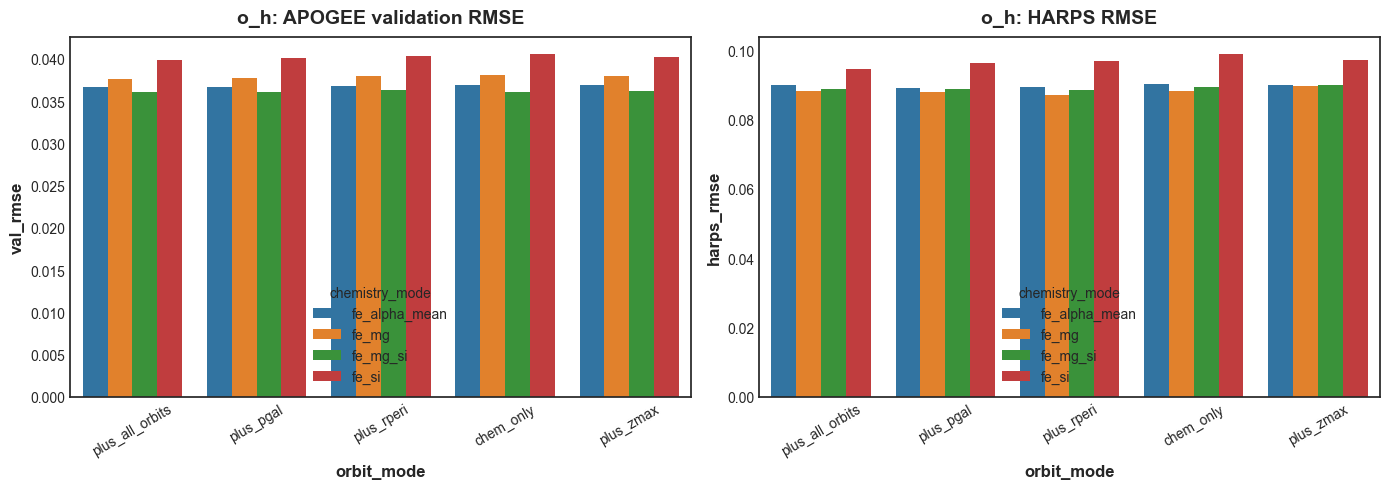

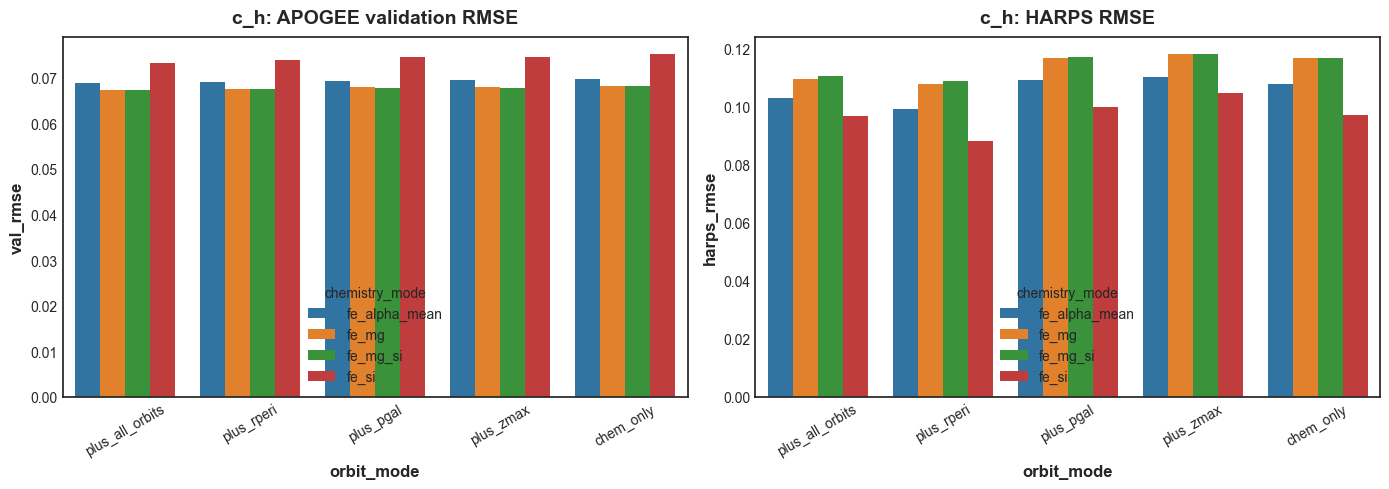

In [26]:
for target in TARGETS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
    target_df = results_df[results_df["target"] == target].copy()

    sns.barplot(data=target_df, x="orbit_mode", y="val_rmse", hue="chemistry_mode", ax=axes[0])
    axes[0].set_title(f"{target}: APOGEE validation RMSE")
    axes[0].tick_params(axis="x", rotation=30)

    sns.barplot(data=target_df, x="orbit_mode", y="harps_rmse", hue="chemistry_mode", ax=axes[1])
    axes[1].set_title(f"{target}: HARPS RMSE")
    axes[1].tick_params(axis="x", rotation=30)

    plt.show()


## [C/Fe] and [O/Fe] vs [Fe/H] for the `fe_h + mg_h + si_h` case

In [27]:
PLOT_CHEMISTRY_MODE = "fe_mg_si"
PLOT_ORBIT_MODE = "chem_only"


def get_predictions_for_configuration(apogee_df, harps_df, target, chemistry_mode, orbit_mode, random_state=42):
    chemistry_features = CHEMISTRY_CONFIGS[chemistry_mode]
    orbit_features = ORBIT_CONFIGS[orbit_mode]
    features = chemistry_features + orbit_features

    train_cols = features + [target]
    apogee_model_df = apogee_df[train_cols].dropna().copy()
    harps_model_df = harps_df[train_cols].dropna().copy()

    X = apogee_model_df[features]
    y = apogee_model_df[target]

    X_train, X_val, y_train, y_val = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=random_state,
    )

    model = LGBMRegressor(
        random_state=random_state,
        verbosity=-1,
        n_jobs=-1,
        objective="regression",
    )
    model.fit(X_train, y_train)

    apogee_plot_df = apogee_model_df.loc[X_val.index, ["fe_h", target]].copy()
    apogee_plot_df["predicted_target"] = model.predict(X_val)
    apogee_plot_df["dataset"] = "APOGEE validation"

    X_harps = harps_model_df[features]
    harps_plot_df = harps_model_df[["fe_h", target]].copy()
    harps_plot_df["predicted_target"] = model.predict(X_harps)
    harps_plot_df["dataset"] = "HARPS"

    return pd.concat([apogee_plot_df, harps_plot_df], ignore_index=True)


def plot_abundance_ratio_vs_feh(prediction_df, target):
    ratio_label = "[O/Fe]" if target == "o_h" else "[C/Fe]"
    prediction_df = prediction_df.copy()
    prediction_df["predicted_ratio"] = prediction_df["predicted_target"] - prediction_df["fe_h"]
    prediction_df["true_ratio"] = prediction_df[target] - prediction_df["fe_h"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

    for ax, dataset_name in zip(axes, ["APOGEE validation", "HARPS"]):
        df_plot = prediction_df[prediction_df["dataset"] == dataset_name]
        ax.scatter(df_plot["fe_h"], df_plot["true_ratio"], s=18, alpha=0.35, label="True")
        ax.scatter(df_plot["fe_h"], df_plot["predicted_ratio"], s=18, alpha=0.35, label="Predicted")
        ax.set_title(dataset_name)
        ax.set_xlabel("[Fe/H]")
        ax.set_ylabel(ratio_label)
        ax.legend()

    fig.suptitle(f"{ratio_label} vs [Fe/H] using {PLOT_CHEMISTRY_MODE} + {PLOT_ORBIT_MODE}")
    plt.show()


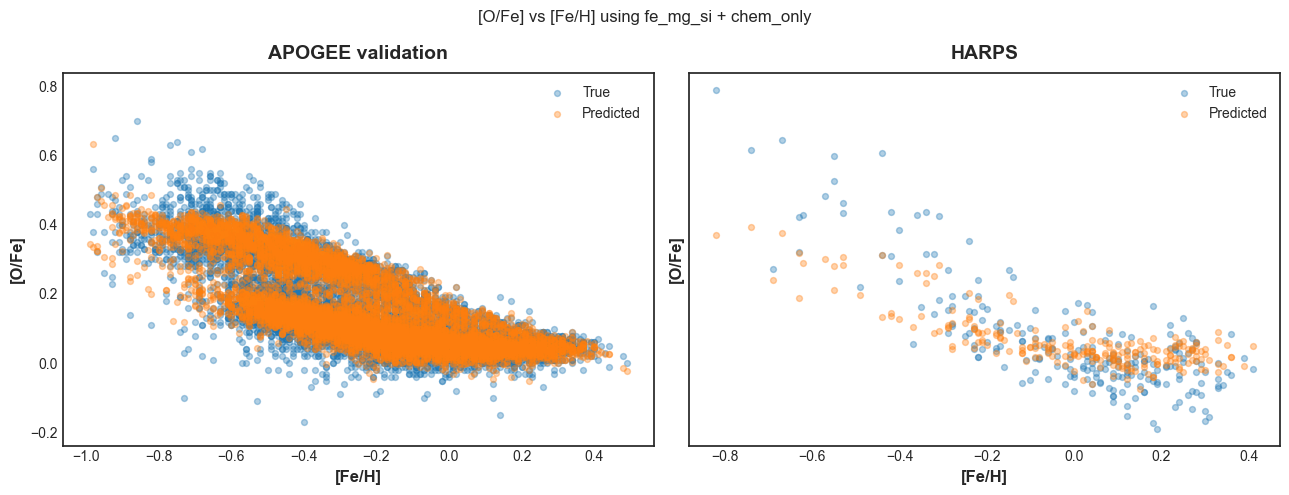

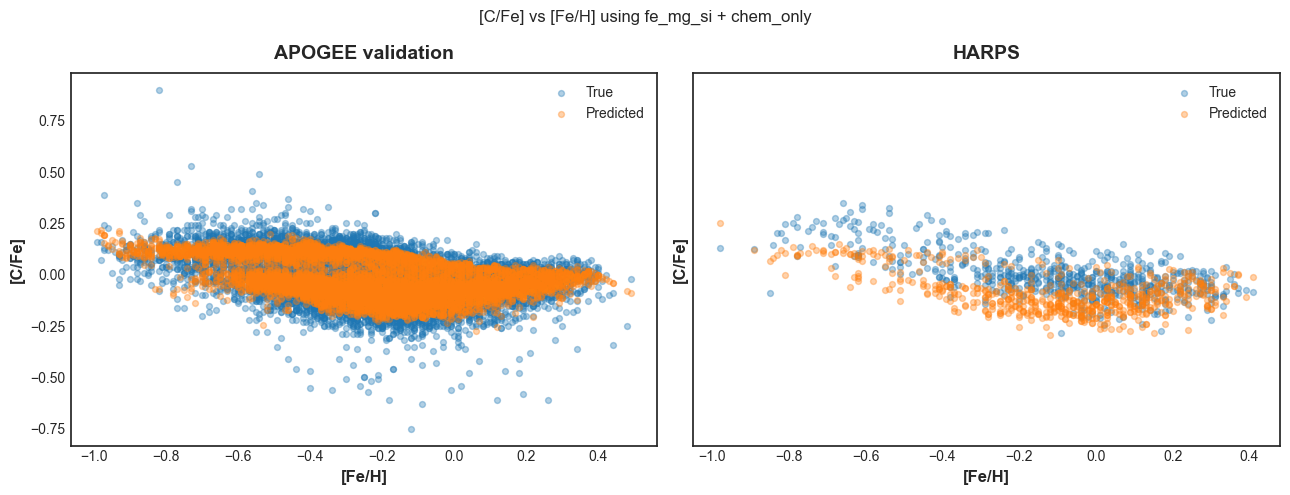

In [28]:
o_prediction_df = get_predictions_for_configuration(
    apogee_df=apogee,
    harps_df=harps,
    target="o_h",
    chemistry_mode=PLOT_CHEMISTRY_MODE,
    orbit_mode=PLOT_ORBIT_MODE,
    random_state=random_state,
)
plot_abundance_ratio_vs_feh(o_prediction_df, target="o_h")

c_prediction_df = get_predictions_for_configuration(
    apogee_df=apogee,
    harps_df=harps,
    target="c_h",
    chemistry_mode=PLOT_CHEMISTRY_MODE,
    orbit_mode=PLOT_ORBIT_MODE,
    random_state=random_state,
)
plot_abundance_ratio_vs_feh(c_prediction_df, target="c_h")
